In [43]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import patheffects
import scipy.optimize
import scipy.stats
from scipy.optimize import minimize, LinearConstraint, Bounds, NonlinearConstraint, linprog
from math import erf
import multiprocessing as mp
# from tqdm import tqdm
from joblib import Parallel, delayed
import itertools
import os
import time
import pandas as pd
import plotly.graph_objects as go

plt.style.use('/Users/ObinnaUkogu/Desktop/custom.mplstyle')
%config InlineBackend.figure_format = 'retina'

In [6]:
# Import experimental data sets on T cell expansion
coverage_data = pd.read_csv('./data/nagashima_fig2.csv')
cross_reactivity_data = pd.read_csv('./data/nagashima_fig3.csv')
day14_abundance_data = pd.read_csv('./data/nagashima_extfig7a.csv')
day2_abundance_data = pd.read_csv('./data/cheng_tableS3.csv')
day2_abundance_data.loc[:,'day2_abundance'] = 100*10**(day2_abundance_data.day2_abundance)
day0_abundance_data = pd.read_csv('./data/wang_tableS2.csv')

full_data = coverage_data.merge(day14_abundance_data[['alt_Strain_Name', 'day14_abundance']], how = 'left', left_on = 'Strain_Name', 
                                right_on = 'alt_Strain_Name').merge(day2_abundance_data[['alt_Strain_Name', 'day2_abundance']], how = 'left', left_on = 'Strain_Name', 
                                                                    right_on = 'alt_Strain_Name').merge(day0_abundance_data[['alt_Strain_Name', 'day0_abundance', 'day28_abundance']], how = 'left', left_on = 'Strain_Name', 
                                                                    right_on = 'alt_Strain_Name')

In [7]:
full_data[['Strain_Name','day0_abundance', 'day2_abundance', 'day14_abundance', 'day28_abundance']].sort_values(by='day0_abundance', 
                                                                          ascending= False)

,Strain_Name,day0_abundance,day2_abundance,day14_abundance,day28_abundance
80,Bacteroides cellulosilyticus DSM 14838,7.937540,1.333415,41.188696,22.408169
95,Parabacteroides sp. D13,3.962174,0.083475,0.020564,0.007956
75,Bacteroides sp. 2_1_22,3.669259,1.387296,18.835215,7.435262
73,Bacteroides sp. 2_1_16,3.582445,2.464561,0.243670,0.075745
69,Bacteroides ovatus ATCC 8483,3.345641,2.548961,0.383181,4.531474
...,...,...,...,...,...
57,Bifidobacterium pseudocatenulatum DSM 20438,NaN,NaN,0.000101,NaN
65,Akkermansia muciniphila ATCC BAA-835,NaN,NaN,3.309003,NaN
91,Parabacteroides merdae ATCC 43184,NaN,NaN,0.001546,NaN
94,Parabacteroides distasonis ATCC 8503,NaN,NaN,0.003397,NaN


In [8]:
full_data[['Strain_Name','day0_abundance', 'day2_abundance', 'day14_abundance', 'day28_abundance']].sort_values(by='day14_abundance', 
                                                                          ascending= False)

,Strain_Name,day0_abundance,day2_abundance,day14_abundance,day28_abundance
80,Bacteroides cellulosilyticus DSM 14838,7.937540,1.333415,41.188696,22.408169
75,Bacteroides sp. 2_1_22,3.669259,1.387296,18.835215,7.435262
72,Bacteroides thetaiotaomicron VPI-5482,3.028590,0.781876,6.405120,4.412580
93,Bacteroides sp. 3_1_19,2.133028,0.216875,4.515190,4.531810
86,Bacteroides dorei 5_1_36/D4,1.728487,0.954538,3.440912,4.310943
...,...,...,...,...,...
48,Granulicatella adiacens ATCC 49175,0.314925,0.008033,0.000000,0.000004
52,Catenibacterium mitsuokai DSM 15897,0.133937,0.001299,0.000000,0.009238
56,Bifidobacterium catenulatum DSM 16992,NaN,NaN,0.000000,NaN
1,Intestinibacter bartlettii DSM 16795,NaN,NaN,0.000000,NaN


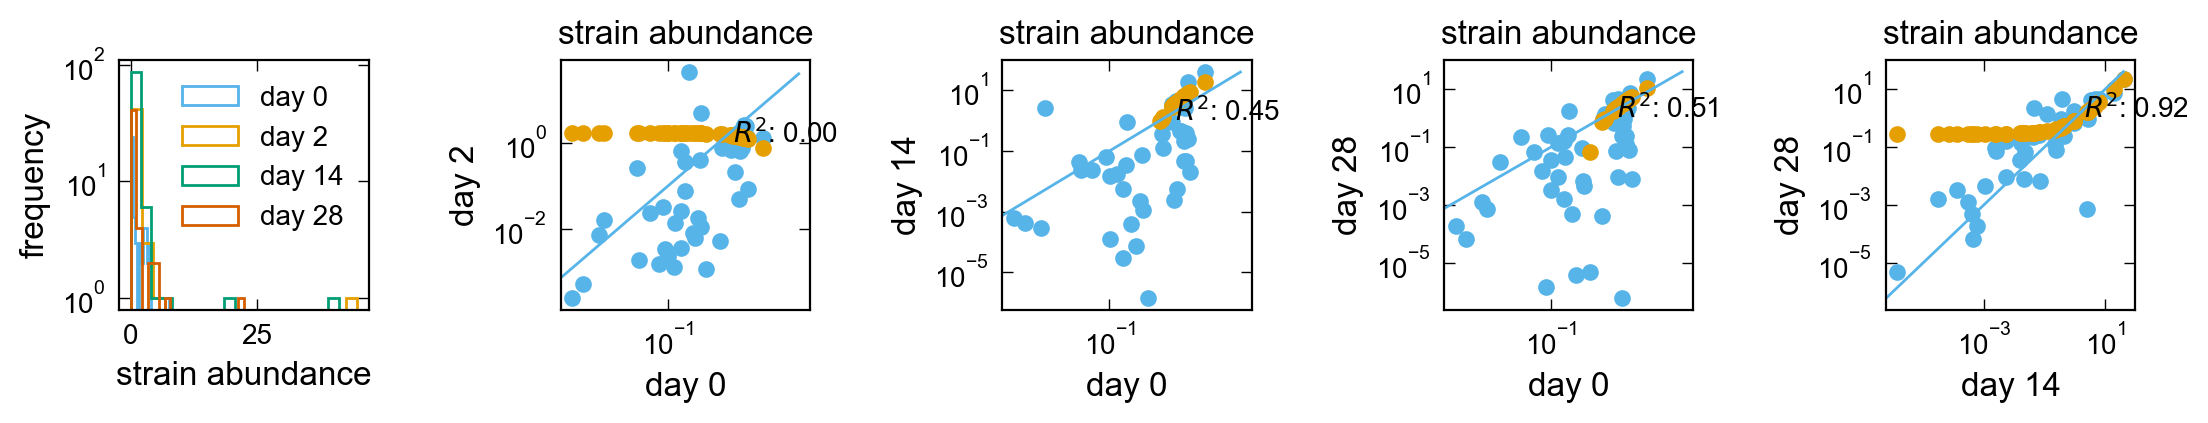

In [62]:
# Plot figures
fig, axs = plt.subplots(1, 5, figsize=(11.0, 2.0), sharex = False, constrained_layout=True)

labels = [['strain abundance', 'frequency'], 
          ['day 0', 'day 2'], ['day 0', 'day 14'], ['day 0', 'day 28'], ['day 14', 'day 28']]
var_list = [["day0_abundance", "day2_abundance"],
            ["day0_abundance", "day14_abundance"],
            ["day0_abundance", "day28_abundance"],
            ["day14_abundance", "day28_abundance"]]

axs[0].hist(full_data.day0_abundance, bins = 20, log = True, histtype = 'step', label = 'day 0');
axs[0].hist(full_data.day2_abundance, bins = 20, log = True, histtype = 'step', label = 'day 2');
axs[0].hist(full_data.day14_abundance, bins = 20, log = True, histtype = 'step', label = 'day 14');
axs[0].hist(full_data.day28_abundance, bins = 20, log = True, histtype = 'step', label = 'day 28');
axs[0].legend()

for i, u in enumerate(var_list):
    axs[i + 1].scatter(full_data[u[0]], full_data[u[1]], marker = 'o')
    mask = ~np.isnan(full_data[u[0]]) & ~np.isnan(full_data[u[1]])
    m, b, r_value, p_value, std_err = scipy.stats.linregress(full_data[u[0]][mask], full_data[u[1]][mask])
    axs[i + 1].scatter(full_data[u[0]][mask], m*full_data[u[0]][mask] + b)
    axs[i + 1].annotate(r'$R^2$: ' + str("{:.2f}".format(r_value**2)), xy=(2,1))

for j, ax in enumerate(axs.flat):
    if j >= 1:
        ax.plot([0, 40], [0,40])
        ax.semilogy()
        ax.semilogx()
        ax.set_title('strain abundance', fontsize = 12) 
        
    ax.set_xlabel(labels[j][0], fontsize = 12)
    ax.set_ylabel(labels[j][1], fontsize = 12)
        
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

In [ ]:
# idea: highlight the relative abundance of the microbes. Signal might be clearer for more abundant microbes

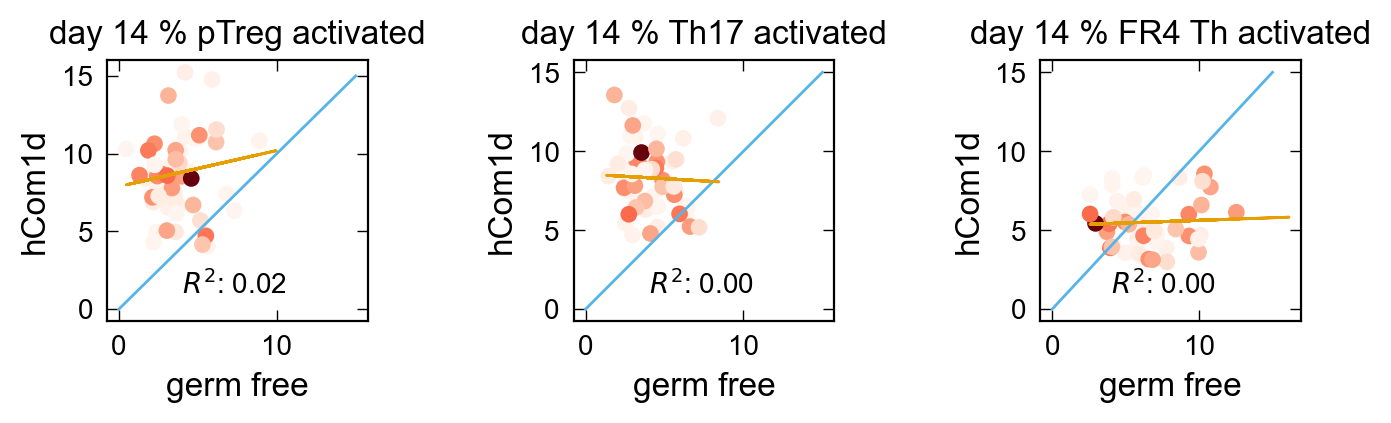

In [69]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

for i, ax in enumerate(axs):

    ax.scatter(full_data[coverage_variables[2*i]], 
               full_data[coverage_variables[2*i + 1]],
               c = full_data['day0_abundance'],
               cmap = 'Reds')
    ax.plot([0, 15], [0,15])

    m, b, r_value, p_value, std_err = scipy.stats.linregress(full_data[coverage_variables[2*i]], full_data[coverage_variables[2*i + 1]])
    ax.plot(full_data[coverage_variables[2*i]], 
            m*full_data[coverage_variables[2*i]] + b)
    ax.annotate(r'$R^2$: ' + str("{:.2f}".format(r_value**2)), xy=(4,1))
    
for j, ax in enumerate(axs.flat):
    # ax.semilogx()
    # ax.semilogy()
    ax.set_xlabel('germ free', fontsize = 12)
    ax.set_ylabel('hCom1d', fontsize = 12)
    ax.set_title('day 14 '+['% pTreg activated', '% Th17 activated', '% FR4 Th activated'][j], fontsize = 12)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

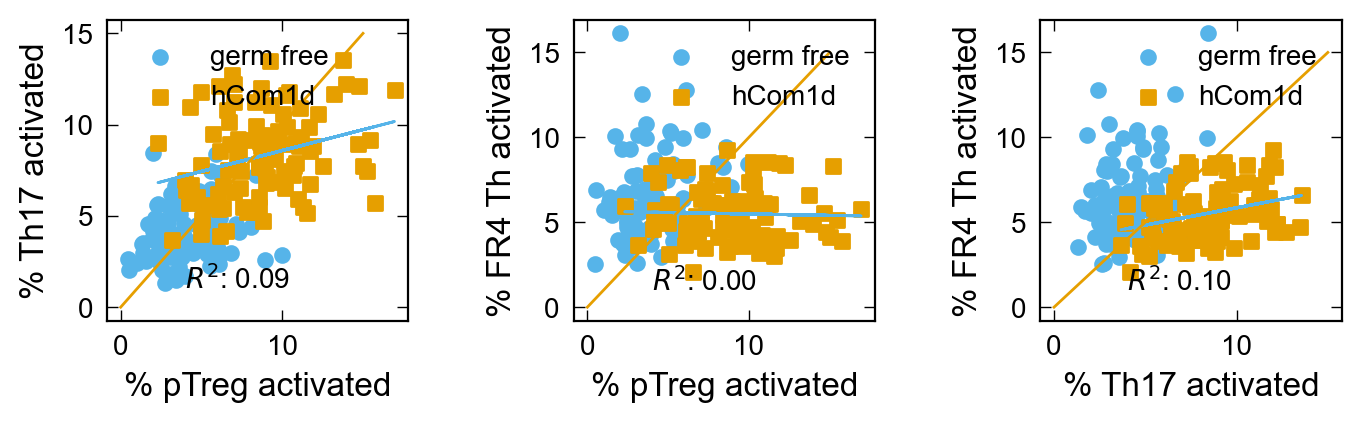

In [54]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']
labels = [['% pTreg activated', '% Th17 activated'], ['% pTreg activated', '% FR4 Th activated'], ['% Th17 activated', '% FR4 Th activated']]
var_list = [[coverage_variables[1], coverage_variables[3]],
            [coverage_variables[1], coverage_variables[5]],
            [coverage_variables[3], coverage_variables[5]]]

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

axs[0].scatter(full_data[coverage_variables[0]], full_data[coverage_variables[2]], marker = 'o', label = 'germ free')
axs[1].scatter(full_data[coverage_variables[0]], full_data[coverage_variables[4]], marker = 'o', label = 'germ free')
axs[2].scatter(full_data[coverage_variables[2]], full_data[coverage_variables[4]], marker = 'o', label = 'germ free')

axs[0].scatter(full_data[coverage_variables[1]], full_data[coverage_variables[3]], marker = 's', label = 'hCom1d')
axs[1].scatter(full_data[coverage_variables[1]], full_data[coverage_variables[5]], marker = 's', label = 'hCom1d')
axs[2].scatter(full_data[coverage_variables[3]], full_data[coverage_variables[5]], marker = 's', label = 'hCom1d')

for i, u in enumerate(var_list):
    m, b, r_value, p_value, std_err = scipy.stats.linregress(full_data[u[0]], full_data[u[1]])
    axs[i].plot(full_data[u[0]], m*full_data[u[0]] + b)
    axs[i].annotate(r'$R^2$: ' + str("{:.2f}".format(r_value**2)), xy=(4,1))

for j, ax in enumerate(axs.flat):
    ax.legend()
    ax.plot([0, 15], [0,15])
    # ax.semilogx()
    # ax.semilogy()
    ax.set_xlabel(labels[j][0], fontsize = 12)
    ax.set_ylabel(labels[j][1], fontsize = 12)
    # ax.set_title(, fontsize = 12)   
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

/opt/anaconda3/envs/erdos_spring_2025/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


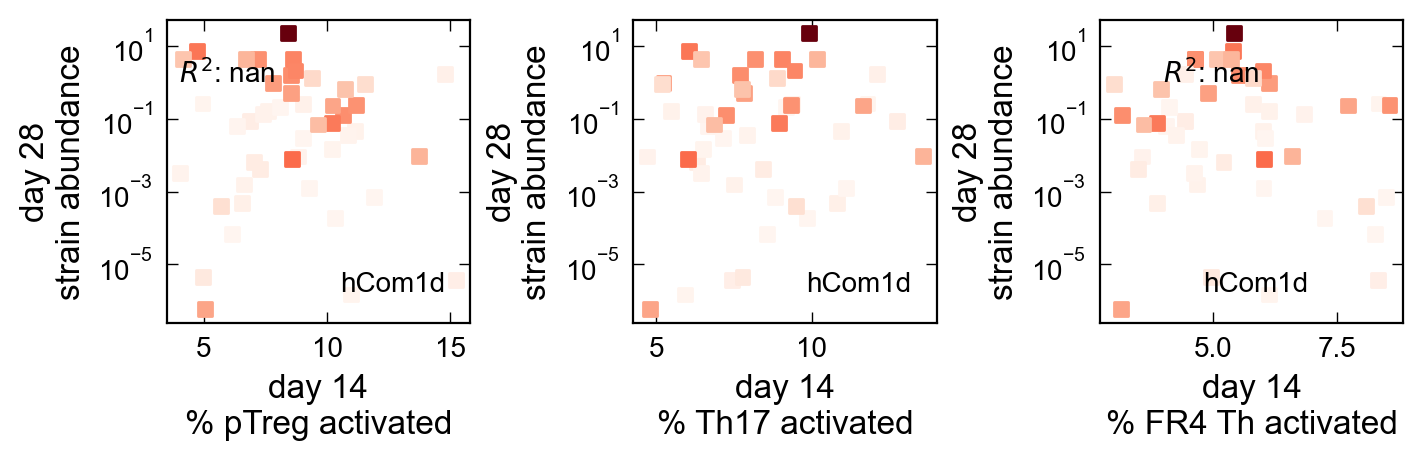

In [68]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

var_list = [coverage_variables[1], coverage_variables[3], coverage_variables[5]]

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.5), sharex = False, constrained_layout=True)

for i, ax in enumerate(axs):

    ax.scatter(full_data[coverage_variables[2*i + 1]], 
               full_data['day28_abundance'], 
               c = full_data['day0_abundance'],
               cmap = 'Reds',
               marker = 's', label = 'hCom1d')

    m, b, r_value, p_value, std_err = scipy.stats.linregress(full_data[var_list[i]], np.log10(full_data['day28_abundance']))
    ax.plot(full_data[var_list[i]], m*full_data[var_list[i]] + b)
    ax.annotate(r'$R^2$: ' + str("{:.2f}".format(r_value**2)), xy=(4,1))

for j, ax in enumerate(axs.flat):
    ax.legend()
    ax.semilogy()
    ax.set_ylabel('day 28\nstrain abundance', fontsize = 12)
    ax.set_xlabel('day 14\n'+['% pTreg activated', '% Th17 activated', '% FR4 Th activated'][j], fontsize = 12)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

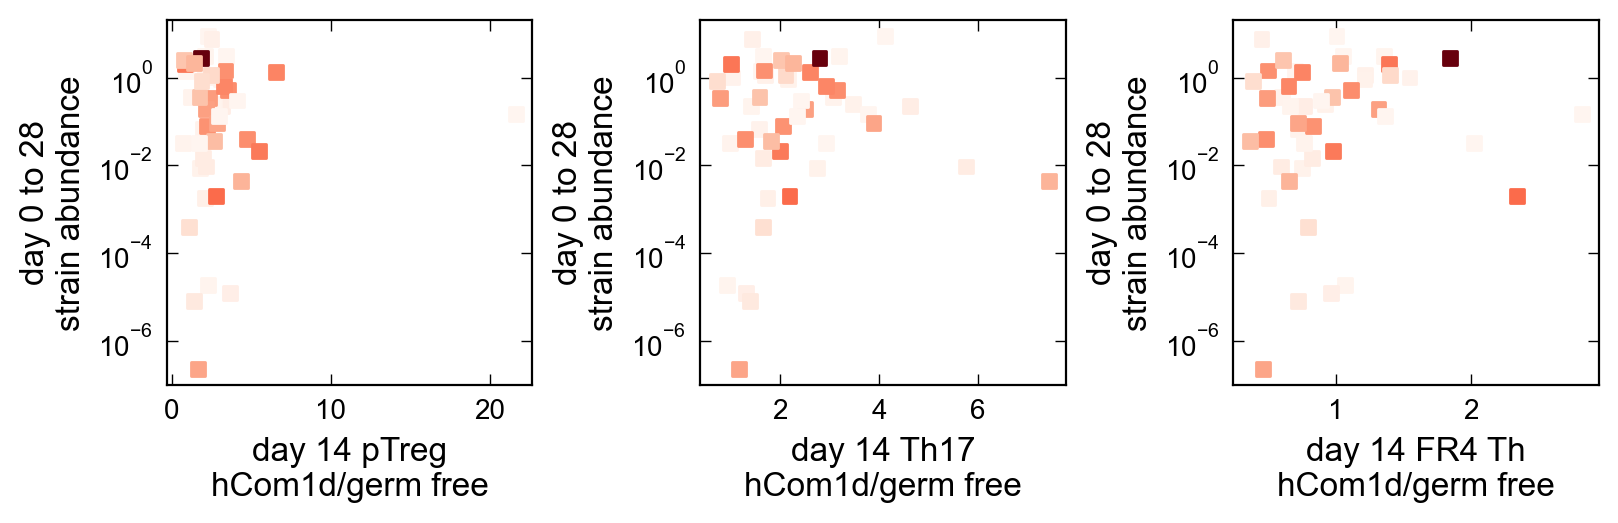

In [66]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(8.0, 2.5), sharex = False, constrained_layout=True)

for i, ax in enumerate(axs):
    ax.scatter(full_data[coverage_variables[2*i + 1]]/full_data[coverage_variables[2*i]], 
               full_data['day28_abundance']/full_data['day0_abundance'], 
               c = full_data['day0_abundance'],
               cmap = 'Reds',
               marker = 's')

for j, ax in enumerate(axs.flat):
    ax.semilogy()
    ax.set_ylabel('day 0 to 28\nstrain abundance', fontsize = 12)
    ax.set_xlabel('day 14 '+['pTreg\nhCom1d/germ free', 'Th17\nhCom1d/germ free', 'FR4 Th\nhCom1d/germ free'][j], fontsize = 12)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

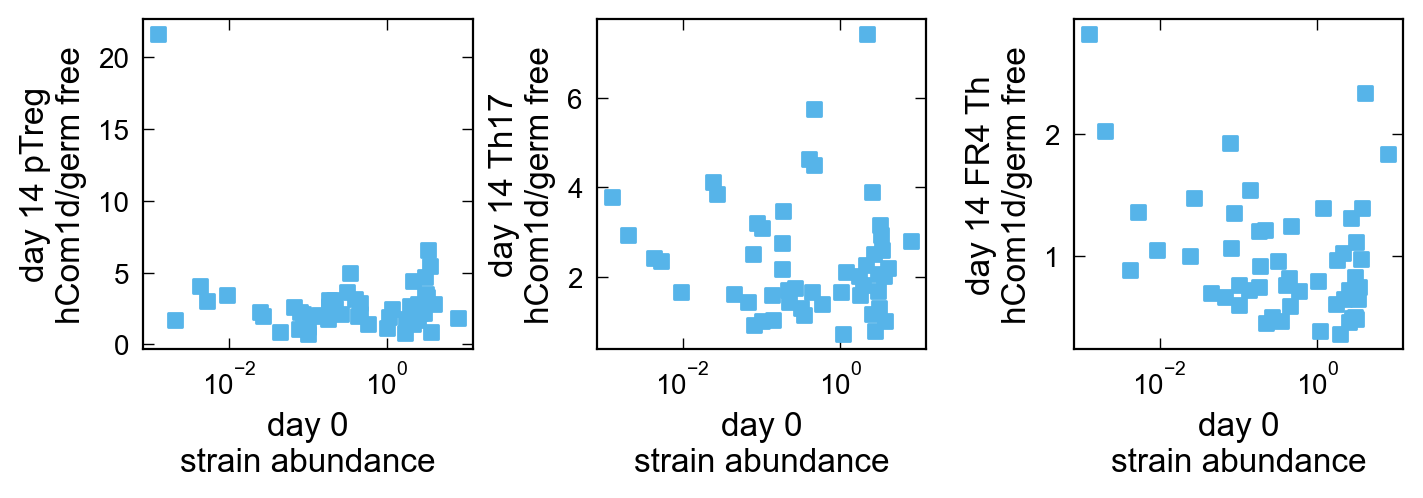

In [67]:
# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.5), sharex = False, constrained_layout=True)

for i, ax in enumerate(axs):
    ax.scatter(full_data['day0_abundance'], 
               full_data[coverage_variables[2*i + 1]]/full_data[coverage_variables[2*i]], marker = 's')

for j, ax in enumerate(axs.flat):
    ax.semilogx()
    ax.set_xlabel('day 0\nstrain abundance', fontsize = 12)
    ax.set_ylabel('day 14 '+['pTreg\nhCom1d/germ free', 'Th17\nhCom1d/germ free', 'FR4 Th\nhCom1d/germ free'][j], fontsize = 12)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)

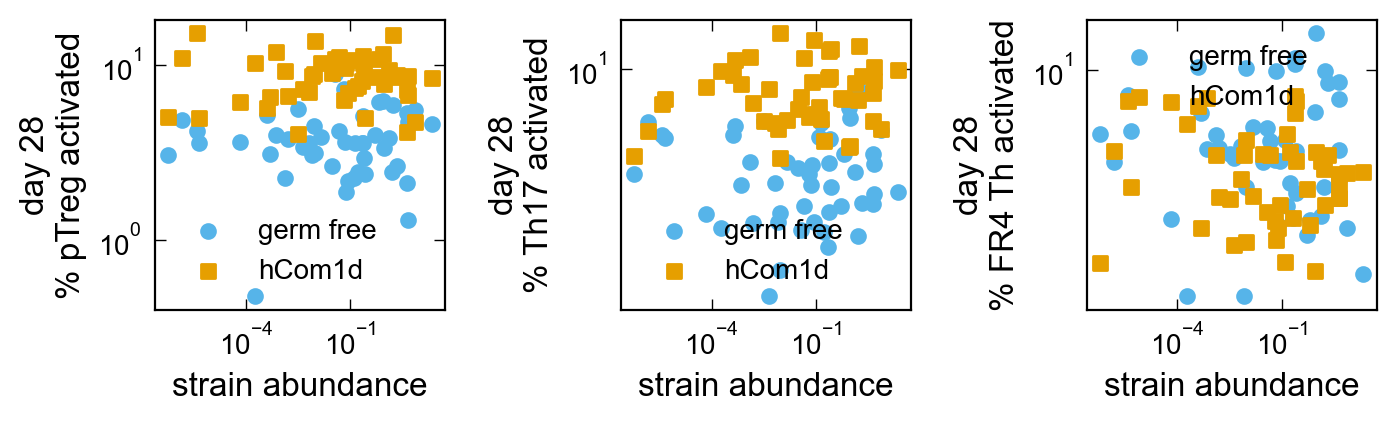

In [42]:
# Build zehn dataset

# Plot figures
coverage_variables = ['GF_pTreg_Average', 'hCom1d_pTreg_Average', 
                      'GF_Th17_Average', 'hCom1d_Th17_Average', 
                      'GF_FR4_Th_Average', 'hCom1d_FR4_Th_Average']

fig, axs = plt.subplots(1, 3, figsize=(7.0, 2.0), sharex = False, constrained_layout=True)

for i, ax in enumerate(axs):

    ax.scatter(full_data['day28_abundance'], full_data[coverage_variables[2*i]], marker = 'o', label = 'germ free')
    ax.scatter(full_data['day28_abundance'], full_data[coverage_variables[2*i + 1]], marker = 's', label = 'hCom1d')
    

for j, ax in enumerate(axs.flat):
    ax.legend()
    ax.semilogx()
    ax.semilogy()
    ax.set_xlabel('strain abundance', fontsize = 12)
    ax.set_ylabel('day 28\n'+['% pTreg activated', '% Th17 activated', '% FR4 Th activated'][j], fontsize = 12)
    ax.set_box_aspect(1)
    ax.minorticks_off()
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.xaxis.set_tick_params(labeltop=False)

# plt.savefig('_figs/fig5_'+comment+'-perf_perturb_design'+'.pdf', format="pdf", transparent=True, dpi=300)